# DATA-VIZ HACK-A-BIT (2026–2027)
## Flight Data 2024
**Course:** 24ADI204 – Data Science and Visualization  
**Team:** 10  
**Dataset:** Flight Data 2024 (Kaggle)  
**Project workflow:** Data collection → Data understanding → Data quality and cleaning → EDA → Feature engineering → Scaling and encoding → Feature selection → PCA → Dashboard and storytelling

## 1. Install and import libraries

In [1]:
!pip -q install kagglehub pandas numpy matplotlib seaborn scikit-learn plotly streamlit

In [2]:
import os, glob, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data collection

In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download("hrishitpatil/flight-data-2024")
print("Dataset downloaded to:", dataset_path)

csv_candidates = glob.glob(os.path.join(dataset_path, "**", "flight_data_2024.csv"), recursive=True)
if not csv_candidates:
    raise FileNotFoundError("flight_data_2024.csv was not found in the downloaded Kaggle dataset.")
file_path = csv_candidates[0]
print("Raw CSV:", file_path)
print("File size (GB):", round(os.path.getsize(file_path) / (1024**3), 2))

100%|██████████| 270M/270M [00:03<00:00, 82.3MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/hrishitpatil/flight-data-2024/versions/2
Raw CSV: /root/.cache/kagglehub/datasets/hrishitpatil/flight-data-2024/versions/2/flight_data_2024.csv
File size (GB): 1.22


## 3. Load the dataset

In [4]:
df = pd.read_csv(file_path, low_memory=False)
print("Dataset loaded successfully.")
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))

Dataset loaded successfully.
Rows: 7,079,081
Columns: 35


## 4. Knowing our data

In [5]:
print("DATASET SHAPE:", df.shape)
print("\nCOLUMN NAMES:")
print(df.columns.tolist())
print("\nDATA TYPES AND NON-NULL COUNTS:")
df.info()

DATASET SHAPE: (7079081, 35)

COLUMN NAMES:
['year', 'month', 'day_of_month', 'day_of_week', 'fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name', 'origin_state_nm', 'dest', 'dest_city_name', 'dest_state_nm', 'crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off', 'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay', 'cancelled', 'cancellation_code', 'diverted', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']

DATA TYPES AND NON-NULL COUNTS:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7079081 entries, 0 to 7079080
Data columns (total 35 columns):
 #   Column               Dtype  
---  ------               -----  
 0   year                 int64  
 1   month                int64  
 2   day_of_month         int64  
 3   day_of_week          int64  
 4   fl_date              object 
 5   op_unique_carrier    object 
 6   op_car

In [6]:
display(df.head())
display(df.describe(include="all").T.head(20))

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237.0,0,0,0,0,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,7079081.0,NaN,NaN,NaN,2024.0,0.0,2024.0,2024.0,2024.0,2024.0,2024.0
month,7079081.0,NaN,NaN,NaN,6.584868,3.396806,1.0,4.0,7.0,10.0,12.0
day_of_month,7079081.0,NaN,NaN,NaN,15.784451,8.786433,1.0,8.0,16.0,23.0,31.0
day_of_week,7079081.0,NaN,NaN,NaN,3.981945,2.012279,1.0,2.0,4.0,6.0,7.0
fl_date,7079081,366,2024-12-01,21764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
op_unique_carrier,7079081,15,WN,1419419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
op_carrier_fl_num,7079080.0,NaN,NaN,NaN,2504.622501,1652.252505,1.0,1151.0,2227.0,3717.0,8819.0
origin,7079081,348,ATL,341910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_city_name,7079081,342,"Chicago, IL",359685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_state_nm,7079081,52,Texas,751839,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:

required_columns = [
    "month", "day_of_week", "op_unique_carrier", "origin", "dest",
    "dep_delay", "arr_delay", "cancelled", "diverted",
    "taxi_out", "taxi_in", "crs_elapsed_time", "actual_elapsed_time",
    "air_time", "distance", "cancellation_code"
]
missing_expected = [c for c in required_columns if c not in df.columns]
print("Expected columns not found:", missing_expected if missing_expected else "None")

Expected columns not found: None


## 5. Missing value analysis

,Missing Count,Missing Percentage
cancellation_code,6982766,98.64
air_time,113814,1.61
actual_elapsed_time,113814,1.61
arr_delay,113814,1.61
arr_time,97854,1.38
wheels_on,97856,1.38
taxi_in,97856,1.38
wheels_off,95734,1.35
taxi_out,95734,1.35
dep_delay,92970,1.31


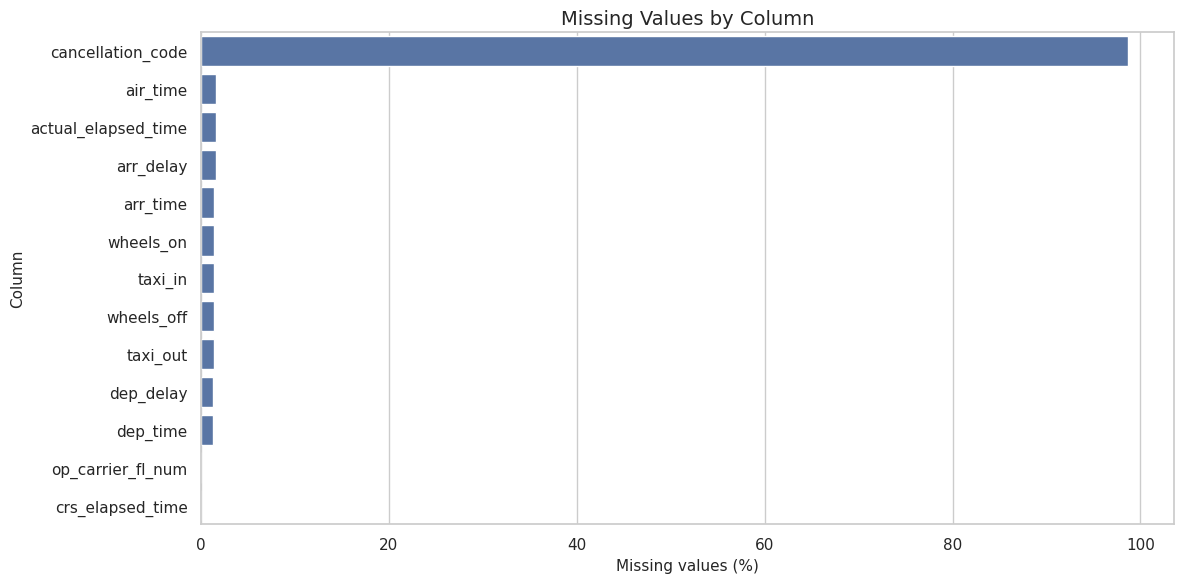

In [8]:
missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})
missing_report = missing_report[missing_report["Missing Count"] > 0].sort_values(
    "Missing Percentage", ascending=False
)
display(missing_report)

if not missing_report.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(data=missing_report.reset_index(), x="Missing Percentage", y="index", color="#4C72B0")
    plt.title("Missing Values by Column")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()

In [10]:
# Checking cancellation and diversion counts
for col in ["cancelled", "diverted"]:
    if col in df.columns:
        print(f"\n{col.upper()} counts:")
        print(df[col].value_counts(dropna=False))


CANCELLED counts:
cancelled
0    6982766
1      96315
Name: count, dtype: int64

DIVERTED counts:
diverted
0    7061582
1      17499
Name: count, dtype: int64


In [11]:
# Comparing missing values in cancelled and non-cancelled flights.
# helping us identify operational fields that are blank because a flight did not operate normally.
if "cancelled" in df.columns:
    cancelled_missing = df.loc[df["cancelled"] == 1].isna().sum()
    non_cancelled_missing = df.loc[df["cancelled"] == 0].isna().sum()
    missing_comparison = pd.DataFrame({
        "Cancelled Flights": cancelled_missing,
        "Non-cancelled Flights": non_cancelled_missing
    })
    display(missing_comparison[missing_comparison.sum(axis=1) > 0].sort_values(
        "Cancelled Flights", ascending=False
    ).head(20))

,Cancelled Flights,Non-cancelled Flights
air_time,96315,17499
arr_delay,96315,17499
arr_time,96315,1539
taxi_in,96315,1541
wheels_on,96315,1541
actual_elapsed_time,96315,17499
wheels_off,95734,0
taxi_out,95734,0
dep_delay,92970,0
dep_time,92659,0


### Missing-value decision
- Blank `cancellation_code` for a flight that was not cancelled is a structural blank, not a measurement failure. It is labelled **Not Cancelled**.
- Missing departure/arrival/taxi/air-time fields can be related to cancelled or diverted flights. They are not blindly replaced with the mean or median.
- Other missing values are reported transparently. Any later imputation is performed inside the modelling pipeline using training/sample data only.

## 6. Duplicate and invalid-value checks

In [12]:
duplicate_count = int(df.duplicated().sum())
print("Duplicate rows:", f"{duplicate_count:,}")

numeric_check_columns = [
    c for c in ["crs_elapsed_time", "distance", "taxi_out", "taxi_in", "air_time"]
    if c in df.columns
]
invalid_counts = {}
for col in numeric_check_columns:
    invalid_counts[col] = int((pd.to_numeric(df[col], errors="coerce") < 0).sum())
print("\nNegative-value counts:")
display(pd.Series(invalid_counts, name="Negative values").to_frame())

Duplicate rows: 0

Negative-value counts:


,Negative values
crs_elapsed_time,1
distance,0
taxi_out,0
taxi_in,0
air_time,0


In [13]:
# Inspecting invalid negative scheduled elapsed time before correcting it
if "crs_elapsed_time" in df.columns:
    invalid_crs = df.loc[df["crs_elapsed_time"] < 0]
    print("Rows with negative CRS elapsed time:", len(invalid_crs))
    display(invalid_crs[[c for c in ["fl_date", "origin", "dest", "cancelled",
                                    "cancellation_code", "crs_elapsed_time"] if c in df.columns]].head())

Rows with negative CRS elapsed time: 1


,fl_date,origin,dest,cancelled,cancellation_code,crs_elapsed_time
1577980,2024-03-27,LAS,RNO,1,B,-160.0


In [15]:
# Cleaning decisions
# Converting impossible negative scheduled elapsed time to missing.
if "crs_elapsed_time" in df.columns:
    df.loc[df["crs_elapsed_time"] < 0, "crs_elapsed_time"] = np.nan

# Preserving cancellation information with an explicit category.
if "cancellation_code" in df.columns:
    df["cancellation_code"] = df["cancellation_code"].fillna("Not Cancelled")

print("Invalid negative CRS elapsed time after correction:",
      int((df["crs_elapsed_time"] < 0).sum()) if "crs_elapsed_time" in df.columns else "Column unavailable")
print("Duplicate rows remain:", int(df.duplicated().sum()))

Invalid negative CRS elapsed time after correction: 0
Duplicate rows remain: 0


## 7. Outlier detection — IQR method

In [16]:
outlier_columns = [
    c for c in ["dep_delay", "arr_delay", "taxi_out", "taxi_in",
                "crs_elapsed_time", "actual_elapsed_time", "air_time", "distance"]
    if c in df.columns
]

iqr_rows = []
for col in outlier_columns:
    series = pd.to_numeric(df[col], errors="coerce").dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())
    iqr_rows.append([col, q1, q3, iqr, lower, upper, count, count / len(series) * 100])

iqr_report = pd.DataFrame(iqr_rows, columns=[
    "Feature", "Q1", "Q3", "IQR", "Lower Bound", "Upper Bound",
    "Outlier Count", "Outlier Percentage"
]).set_index("Feature")
display(iqr_report.round(2))

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
Feature,,,,,,,
dep_delay,-6.0,9.0,15.0,-28.5,31.5,909066,13.01
arr_delay,-15.0,9.0,24.0,-51.0,45.0,670540,9.63
taxi_out,12.0,21.0,9.0,-1.5,34.5,355622,5.09
taxi_in,5.0,10.0,5.0,-2.5,17.5,466184,6.68
crs_elapsed_time,93.0,177.0,84.0,-33.0,303.0,360025,5.09
actual_elapsed_time,88.0,172.0,84.0,-38.0,298.0,341997,4.91
air_time,63.0,145.0,82.0,-60.0,268.0,349654,5.02
distance,399.0,1069.0,670.0,-606.0,2074.0,420064,5.93


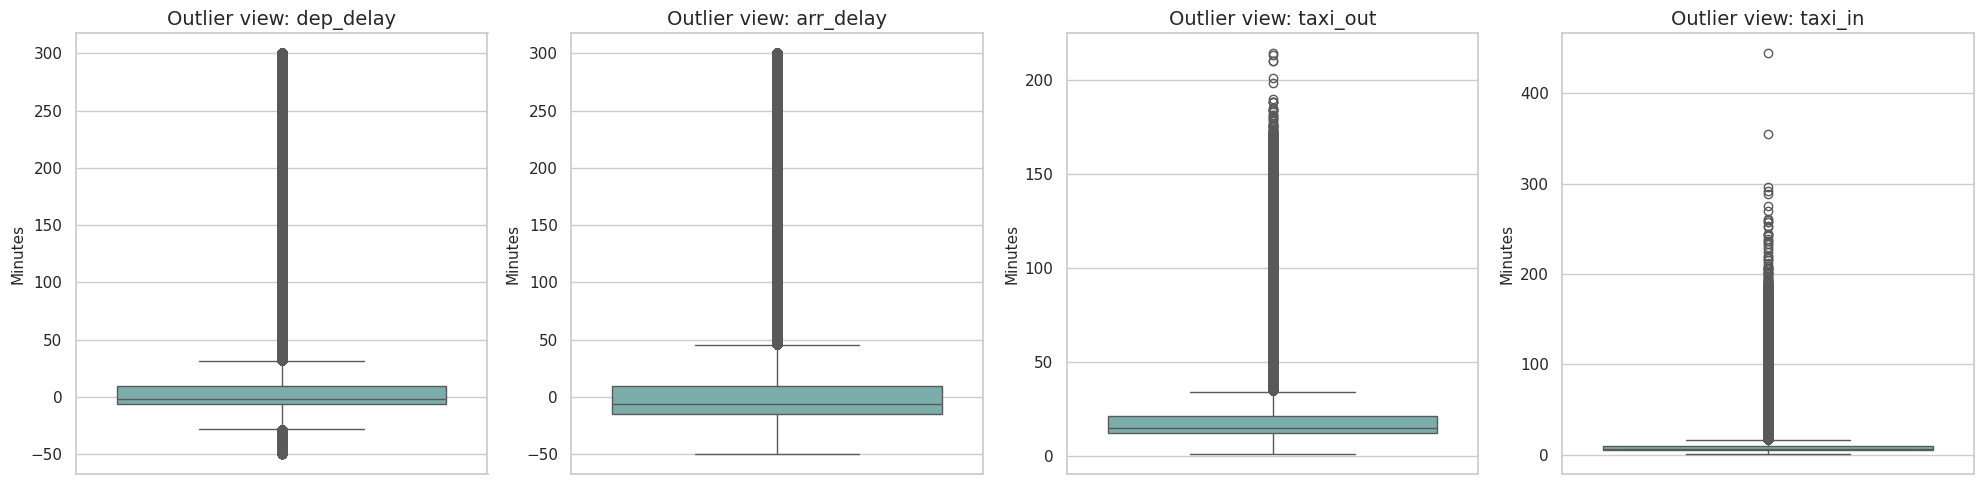

In [17]:
# Coloured boxplots. Delay plots are clipped only for readability; original data is not changed.
box_features = [c for c in ["dep_delay", "arr_delay", "taxi_out", "taxi_in"] if c in df.columns]
fig, axes = plt.subplots(1, len(box_features), figsize=(5 * len(box_features), 5))
if len(box_features) == 1:
    axes = [axes]
for ax, col in zip(axes, box_features):
    values = df[col].dropna()
    if "delay" in col:
        values = values.clip(-50, 300)
    sns.boxplot(y=values, ax=ax, color="#72B7B2")
    ax.set_title(f"Outlier view: {col}")
    ax.set_ylabel("Minutes")
plt.tight_layout()
plt.show()

## 8. Outlier detection — Z-score method

In [18]:
zscore_rows = []
for col in outlier_columns:
    series = pd.to_numeric(df[col], errors="coerce").dropna()
    mean, std = series.mean(), series.std()
    if std == 0 or pd.isna(std):
        count = 0
    else:
        count = int((((series - mean) / std).abs() > 3).sum())
    zscore_rows.append([col, count, count / len(series) * 100 if len(series) else 0])

zscore_report = pd.DataFrame(zscore_rows, columns=[
    "Feature", "Z-score Outlier Count (|z| > 3)", "Outlier Percentage"
]).set_index("Feature")
display(zscore_report.round(2))

,Z-score Outlier Count (|z| > 3),Outlier Percentage
Feature,,
dep_delay,100953,1.45
arr_delay,98400,1.41
taxi_out,124843,1.79
taxi_in,129604,1.86
crs_elapsed_time,100264,1.42
actual_elapsed_time,91593,1.31
air_time,91933,1.32
distance,61230,0.86


### Outlier decision
IQR and Z-score identify unusually high or low values; they do not prove that a flight record is incorrect. Large delays and long flights can be genuine events. Therefore, this project flags and studies outliers instead of deleting all of them. Delay values are clipped only inside selected plots to make the main distribution easier to see.

## 9. Automatic data quality report

In [19]:
quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Count": df.isna().sum().values,
    "Missing Percentage": (df.isna().mean().values * 100).round(2),
    "Unique Values": df.nunique(dropna=True).values
})
print("DATA QUALITY REPORT")
print("=" * 70)
print("Total records:", f"{len(df):,}")
print("Total features:", len(df.columns))
print("Duplicate rows:", f"{df.duplicated().sum():,}")
print("Total missing cells:", f"{df.isna().sum().sum():,}")
display(quality_report)
quality_report.to_csv("/content/data_quality_report.csv", index=False)
print("Saved: /content/data_quality_report.csv")

DATA QUALITY REPORT
Total records: 7,079,081
Total features: 35
Duplicate rows: 0
Total missing cells: 1,012,108


,Column,Data Type,Missing Count,Missing Percentage,Unique Values
0,year,int64,0,0.00,1
1,month,int64,0,0.00,12
2,day_of_month,int64,0,0.00,31
3,day_of_week,int64,0,0.00,7
4,fl_date,object,0,0.00,366
5,op_unique_carrier,object,0,0.00,15
6,op_carrier_fl_num,float64,1,0.00,6862
7,origin,object,0,0.00,348
8,origin_city_name,object,0,0.00,342
9,origin_state_nm,object,0,0.00,52


Saved: /content/data_quality_report.csv


## 10. Descriptive statistics

In [20]:
stats_columns = [c for c in [
    "dep_delay", "arr_delay", "taxi_out", "taxi_in",
    "crs_elapsed_time", "actual_elapsed_time", "air_time", "distance"
] if c in df.columns]

descriptive_stats = df[stats_columns].describe().T
descriptive_stats["Variance"] = df[stats_columns].var()
descriptive_stats["Skewness"] = df[stats_columns].skew()
descriptive_stats["Kurtosis"] = df[stats_columns].kurt()
display(descriptive_stats.round(2))

,count,mean,std,min,25%,50%,75%,max,Variance,Skewness,Kurtosis
dep_delay,6986111.0,12.68,56.06,-96.0,-6.0,-2.0,9.0,3777.0,3142.72,11.06,225.37
arr_delay,6965267.0,7.10,57.99,-126.0,-15.0,-6.0,9.0,3803.0,3362.99,10.08,198.14
taxi_out,6983347.0,17.90,9.68,1.0,12.0,15.0,21.0,214.0,93.65,3.49,23.60
taxi_in,6981225.0,8.33,6.84,1.0,5.0,6.0,10.0,444.0,46.85,5.07,60.25
crs_elapsed_time,7079079.0,146.77,72.39,6.0,93.0,130.0,177.0,1326.0,5239.85,1.39,2.39
actual_elapsed_time,6965267.0,141.22,72.31,15.0,88.0,125.0,172.0,792.0,5228.42,1.37,2.35
air_time,6965267.0,115.00,70.37,5.0,63.0,98.0,145.0,723.0,4951.87,1.40,2.45
distance,7079081.0,833.91,596.25,11.0,399.0,680.0,1069.0,5095.0,355518.35,1.46,2.69


## 11. Univariate analysis — distributions

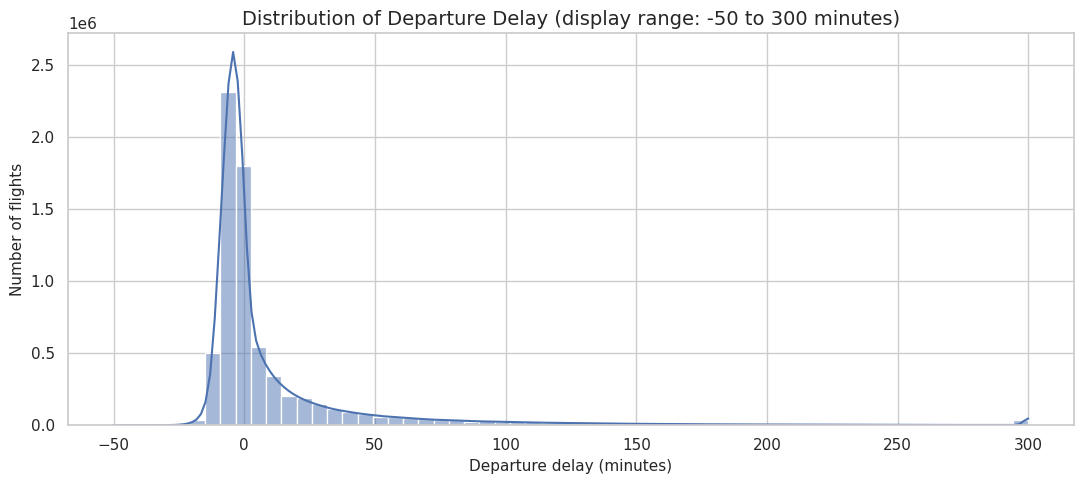

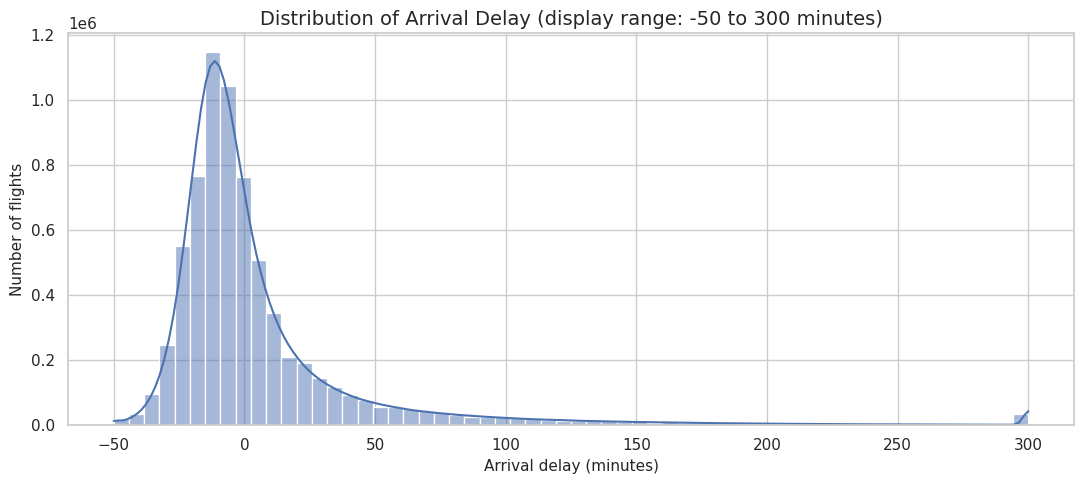

In [21]:
for col, title, xlabel in [
    ("dep_delay", "Distribution of Departure Delay", "Departure delay (minutes)"),
    ("arr_delay", "Distribution of Arrival Delay", "Arrival delay (minutes)")
]:
    if col in df.columns:
        values = df[col].dropna().clip(-50, 300)
        plt.figure(figsize=(11, 5))
        sns.histplot(values, bins=60, kde=True, color="#4C72B0")
        plt.title(title + " (display range: -50 to 300 minutes)")
        plt.xlabel(xlabel)
        plt.ylabel("Number of flights")
        plt.tight_layout()
        plt.show()

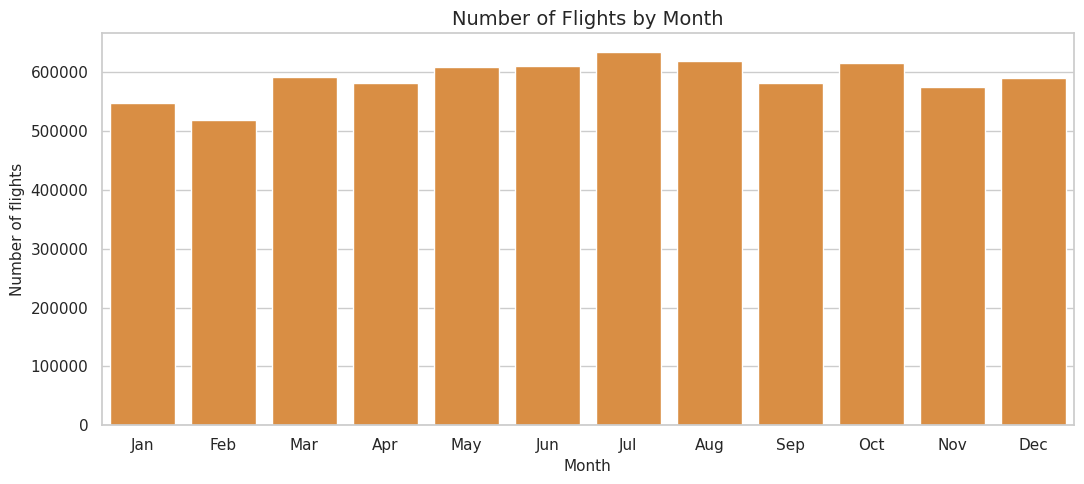

In [22]:
# Flight volume by month
if "month" in df.columns:
    monthly_count = df.groupby("month").size().reindex(range(1, 13), fill_value=0)
    plt.figure(figsize=(11, 5))
    sns.barplot(x=monthly_count.index, y=monthly_count.values, color="#F28E2B")
    plt.title("Number of Flights by Month")
    plt.xlabel("Month")
    plt.ylabel("Number of flights")
    plt.xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
    plt.tight_layout()
    plt.show()

## 12. Bivariate and categorical analysis

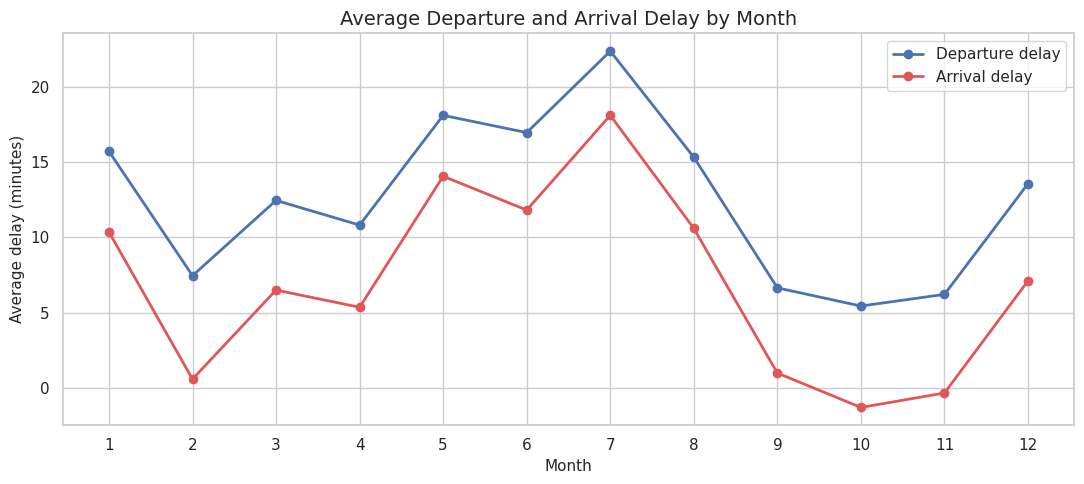

,dep_delay,arr_delay
month,,
1,15.70,10.35
2,7.46,0.59
3,12.45,6.50
4,10.81,5.36
5,18.09,14.05
6,16.95,11.81
7,22.35,18.09
8,15.31,10.59
9,6.65,1.00


In [23]:
# Average departure and arrival delay by month
if {"month", "dep_delay", "arr_delay"}.issubset(df.columns):
    monthly_delay = df.groupby("month")[["dep_delay", "arr_delay"]].mean().reindex(range(1, 13))
    ax = monthly_delay.plot(marker="o", linewidth=2, figsize=(11, 5), color=["#4C72B0", "#E15759"])
    ax.set_title("Average Departure and Arrival Delay by Month")
    ax.set_xlabel("Month")
    ax.set_ylabel("Average delay (minutes)")
    ax.set_xticks(range(1, 13))
    ax.legend(["Departure delay", "Arrival delay"])
    plt.tight_layout()
    plt.show()
    display(monthly_delay.round(2))

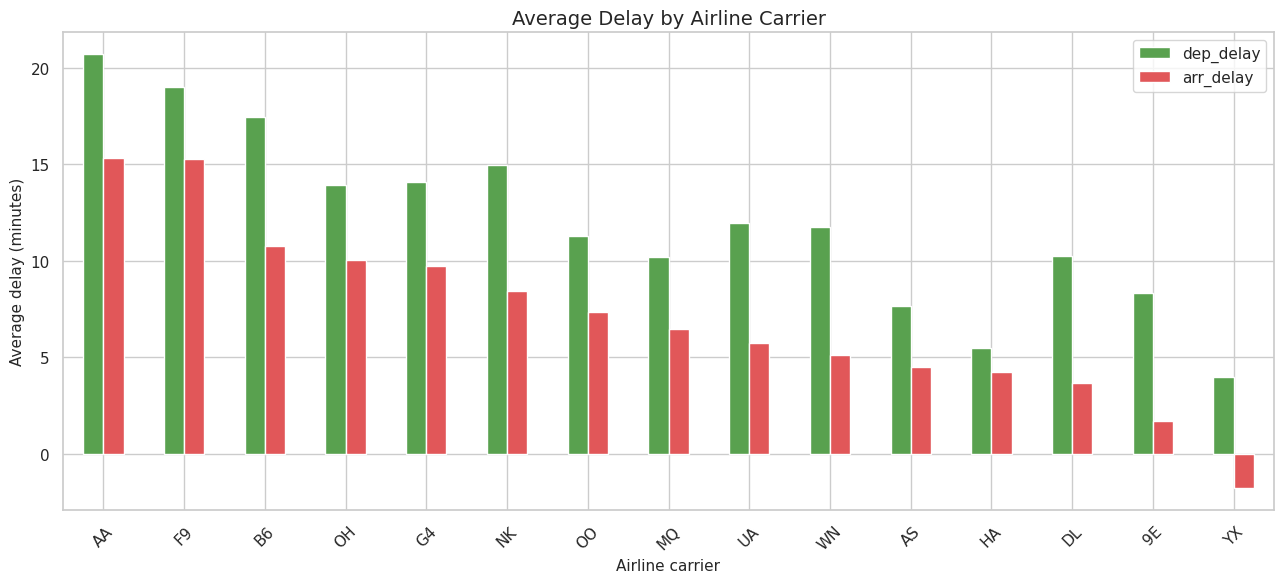

,dep_delay,arr_delay
op_unique_carrier,,
AA,20.70,15.31
F9,19.00,15.25
B6,17.46,10.74
OH,13.94,10.03
G4,14.05,9.71
NK,14.96,8.42
OO,11.28,7.36
MQ,10.18,6.46
UA,11.96,5.74


In [24]:
# Average delay by airline carrier
if {"op_unique_carrier", "dep_delay", "arr_delay"}.issubset(df.columns):
    carrier_delay = df.groupby("op_unique_carrier")[["dep_delay", "arr_delay"]].mean()
    carrier_delay = carrier_delay.sort_values("arr_delay", ascending=False)
    ax = carrier_delay.plot(kind="bar", figsize=(13, 6), color=["#59A14F", "#E15759"])
    ax.set_title("Average Delay by Airline Carrier")
    ax.set_xlabel("Airline carrier")
    ax.set_ylabel("Average delay (minutes)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    display(carrier_delay.round(2))

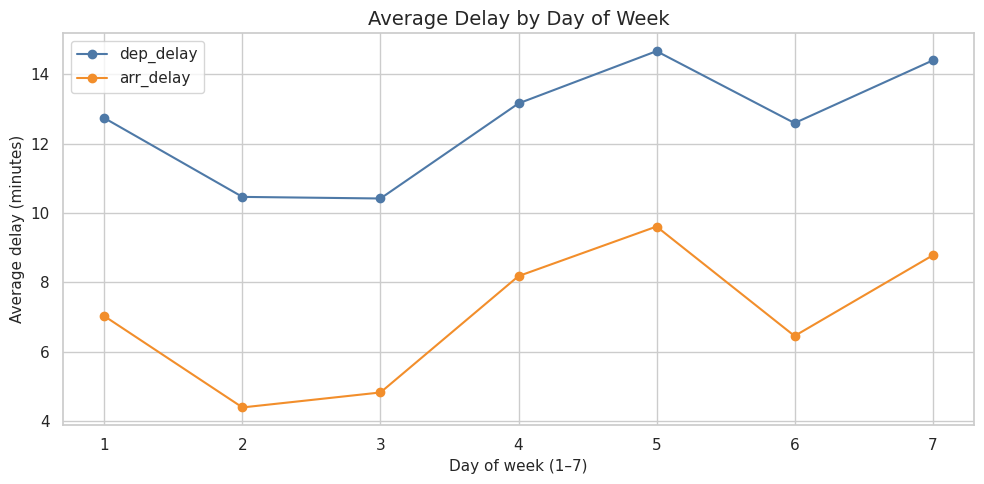

,dep_delay,arr_delay
day_of_week,,
1,12.73,7.03
2,10.46,4.39
3,10.42,4.83
4,13.16,8.18
5,14.66,9.61
6,12.59,6.45
7,14.39,8.77


In [25]:
# Day-of-week average delays
if {"day_of_week", "dep_delay", "arr_delay"}.issubset(df.columns):
    day_delay = df.groupby("day_of_week")[["dep_delay", "arr_delay"]].mean()
    ax = day_delay.plot(marker="o", figsize=(10, 5), color=["#4E79A7", "#F28E2B"])
    ax.set_title("Average Delay by Day of Week")
    ax.set_xlabel("Day of week (1–7)")
    ax.set_ylabel("Average delay (minutes)")
    plt.tight_layout()
    plt.show()
    display(day_delay.round(2))

In [26]:
# Correlation between departure and arrival delay
if {"dep_delay", "arr_delay"}.issubset(df.columns):
    delay_corr = df["dep_delay"].corr(df["arr_delay"])
    print("Correlation between departure and arrival delay:", round(delay_corr, 3))
    print("Interpretation: a strong positive association means flights with higher departure delays tend to have higher arrival delays.")
    print("Correlation does not prove causation.")

Correlation between departure and arrival delay: 0.971
Interpretation: a strong positive association means flights with higher departure delays tend to have higher arrival delays.
Correlation does not prove causation.


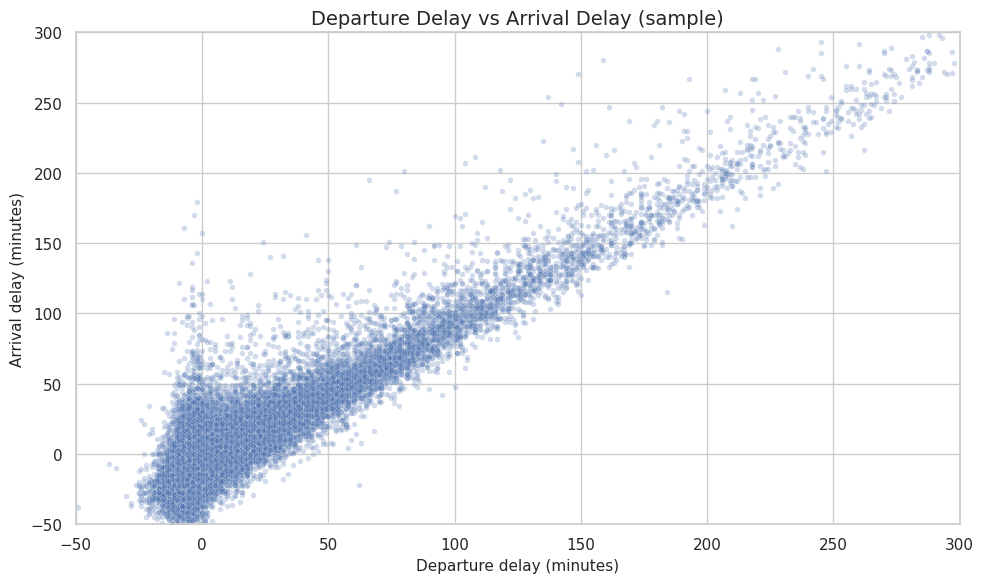

In [27]:
# Sample points for readable scatterplots; original dataset is not reduced.
if {"dep_delay", "arr_delay"}.issubset(df.columns):
    scatter_data = df[["dep_delay", "arr_delay"]].dropna()
    scatter_data = scatter_data.sample(n=min(50000, len(scatter_data)), random_state=42)
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=scatter_data, x="dep_delay", y="arr_delay", alpha=0.25, s=16, color="#4C72B0")
    plt.title("Departure Delay vs Arrival Delay (sample)")
    plt.xlabel("Departure delay (minutes)")
    plt.ylabel("Arrival delay (minutes)")
    plt.xlim(-50, 300); plt.ylim(-50, 300)
    plt.tight_layout()
    plt.show()

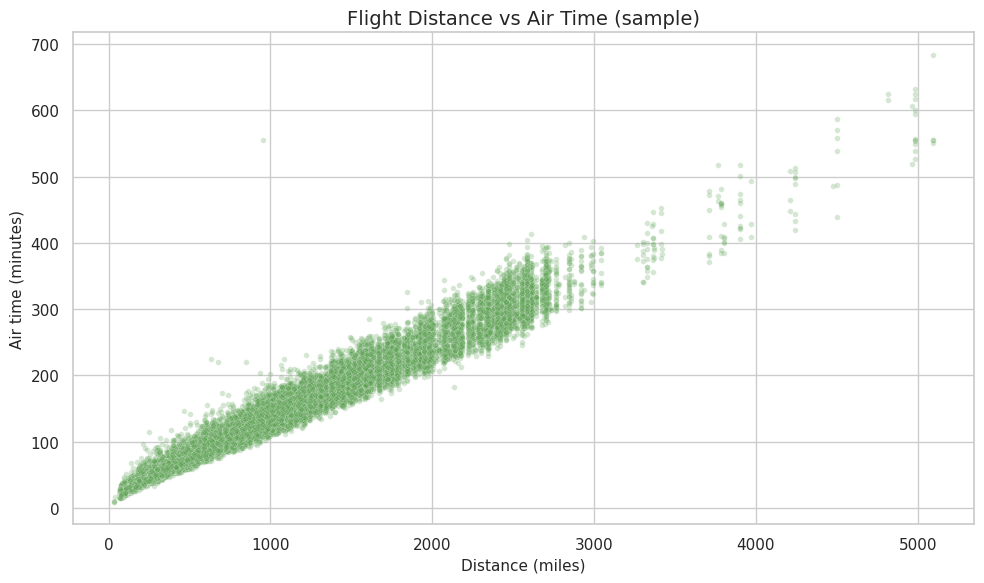

In [28]:
# Distance and air time relationship
if {"distance", "air_time"}.issubset(df.columns):
    distance_sample = df[["distance", "air_time"]].dropna()
    distance_sample = distance_sample.sample(n=min(50000, len(distance_sample)), random_state=42)
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=distance_sample, x="distance", y="air_time", alpha=0.25, s=16, color="#59A14F")
    plt.title("Flight Distance vs Air Time (sample)")
    plt.xlabel("Distance (miles)")
    plt.ylabel("Air time (minutes)")
    plt.tight_layout()
    plt.show()

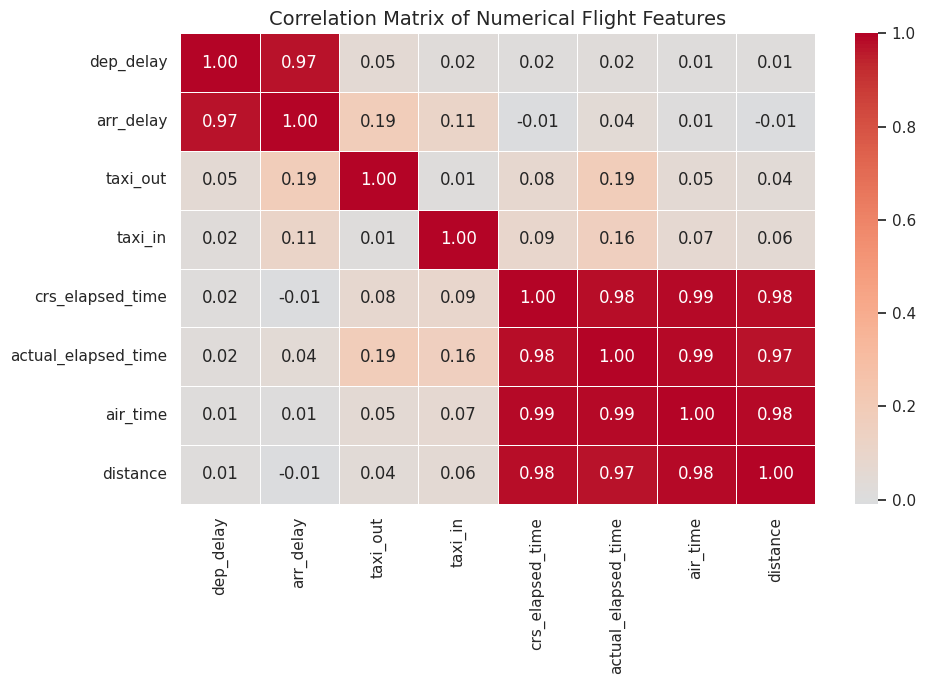

In [29]:
# Correlation heatmap
corr_cols = [c for c in [
    "dep_delay", "arr_delay", "taxi_out", "taxi_in",
    "crs_elapsed_time", "actual_elapsed_time", "air_time", "distance"
] if c in df.columns]
correlation_matrix = df[corr_cols].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=.5)
plt.title("Correlation Matrix of Numerical Flight Features")
plt.tight_layout()
plt.show()

## 13. Feature engineering
Create useful calendar and route features. These are derived from existing columns and do not represent live flight information or delay predictions.

In [31]:
# Working on the cleaned full dataframe.
if "month" in df.columns:
    df["month"] = pd.to_numeric(df["month"], errors="coerce")
if "day_of_week" in df.columns:
    df["day_of_week"] = pd.to_numeric(df["day_of_week"], errors="coerce")

if {"origin", "dest"}.issubset(df.columns):
    df["route"] = df["origin"].astype("string") + "-" + df["dest"].astype("string")

if "day_of_week" in df.columns:
    df["is_weekend"] = df["day_of_week"].isin([6, 7]).astype("int8")

if "dep_delay" in df.columns:
    df["departure_delay_category"] = pd.cut(
        df["dep_delay"],
        bins=[-np.inf, 0, 15, 60, np.inf],
        labels=["On time/early", "Small delay", "Moderate delay", "High delay"]
    )

display(df[[c for c in ["month", "day_of_week", "route", "is_weekend",
                        "dep_delay", "departure_delay_category"] if c in df.columns]].head())

,month,day_of_week,route,is_weekend,dep_delay,departure_delay_category
0,1,1,JFK-DTW,0,-5.0,On time/early
1,1,1,MSP-CLE,0,-14.0,On time/early
2,1,1,JFK-RIC,0,-4.0,On time/early
3,1,1,RIC-JFK,0,-7.0,On time/early
4,1,1,DTW-MKE,0,-5.0,On time/early


In [32]:
# Checking skewness before transformation
skew_before = df[stats_columns].skew()
display(skew_before.rename("Skewness before transformation").to_frame().round(2))

,Skewness before transformation
dep_delay,11.06
arr_delay,10.08
taxi_out,3.49
taxi_in,5.07
crs_elapsed_time,1.39
actual_elapsed_time,1.37
air_time,1.40
distance,1.46


,Before,After Yeo-Johnson
dep_delay,12.59,-0.26
arr_delay,11.38,0.11
taxi_out,3.51,-0.02
taxi_in,5.15,0.01
air_time,1.41,-0.00
distance,1.46,-0.02


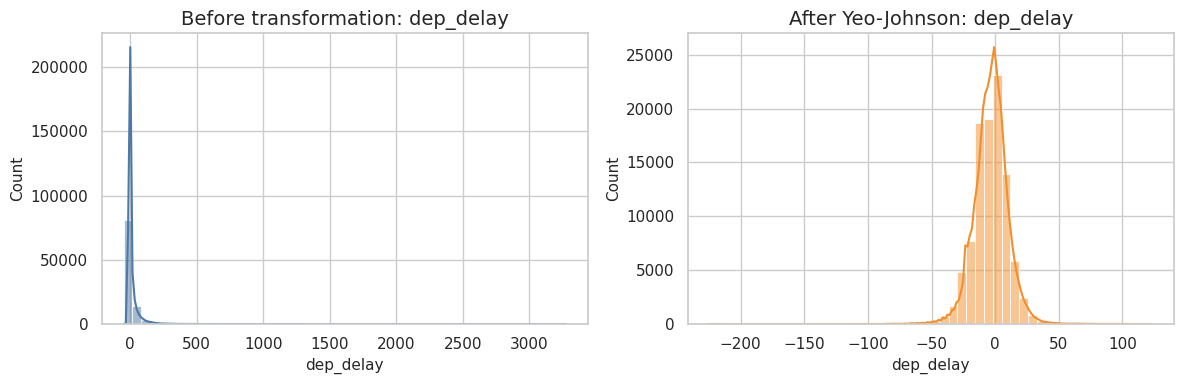

In [33]:
# Using Yeo-Johnson transformation on a manageable sample of numeric features.
# It supports both positive and negative values, including early departures.
transform_features = [c for c in ["dep_delay", "arr_delay", "taxi_out", "taxi_in", "air_time", "distance"] if c in df.columns]
transform_sample = df[transform_features].dropna().sample(
    n=min(100000, len(df[transform_features].dropna())), random_state=42
)
power_transformer = PowerTransformer(method="yeo-johnson", standardize=False)
transformed_values = power_transformer.fit_transform(transform_sample)
transformed_df = pd.DataFrame(transformed_values, columns=transform_features)

skew_comparison = pd.DataFrame({
    "Before": transform_sample.skew(),
    "After Yeo-Johnson": transformed_df.skew()
})
display(skew_comparison.round(2))

feature_to_plot = "dep_delay" if "dep_delay" in transform_features else transform_features[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(transform_sample[feature_to_plot], bins=50, kde=True, ax=axes[0], color="#4E79A7")
axes[0].set_title(f"Before transformation: {feature_to_plot}")
sns.histplot(transformed_df[feature_to_plot], bins=50, kde=True, ax=axes[1], color="#F28E2B")
axes[1].set_title(f"After Yeo-Johnson: {feature_to_plot}")
plt.tight_layout()
plt.show()

## 14. Feature selection, encoding, scaling and PCA
The following stage uses a reproducible sample because PCA on all 7 million rows is expensive in Colab. Numeric missing values are imputed with the median inside the pipeline. Carrier and month are encoded. Features with very high missingness or identifiers are not used as PCA inputs.

In [34]:
pca_numeric = [c for c in ["dep_delay", "arr_delay", "taxi_out", "taxi_in",
                           "crs_elapsed_time", "actual_elapsed_time", "air_time", "distance"]
               if c in df.columns]
pca_categorical = [c for c in ["op_unique_carrier", "month"] if c in df.columns]

pca_source = df[pca_numeric + pca_categorical].copy()
pca_source = pca_source.replace([np.inf, -np.inf], np.nan)
pca_source = pca_source.sample(n=min(100000, len(pca_source)), random_state=42)
print("PCA sample shape:", pca_source.shape)
print("Numeric features:", pca_numeric)
print("Categorical features:", pca_categorical)

PCA sample shape: (100000, 10)
Numeric features: ['dep_delay', 'arr_delay', 'taxi_out', 'taxi_in', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance']
Categorical features: ['op_unique_carrier', 'month']


In [35]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, pca_numeric),
    ("cat", categorical_pipeline, pca_categorical)
])

X_prepared = preprocessor.fit_transform(pca_source)
print("Transformed feature matrix shape:", X_prepared.shape)

Transformed feature matrix shape: (100000, 35)


In [36]:
# Removing constant features before PCA
variance_filter = VarianceThreshold(threshold=0.0)
X_selected = variance_filter.fit_transform(X_prepared)
print("Features after removing zero-variance columns:", X_selected.shape[1])

Features after removing zero-variance columns: 35


In [37]:
# PCA: retain enough components to explain 90% of variance (up to available feature count)
pca = PCA(n_components=0.90, svd_solver="full", random_state=42)
principal_components = pca.fit_transform(X_selected)

explained = pca.explained_variance_ratio_
print("Number of principal components selected:", pca.n_components_)
print("Total explained variance:", round(explained.sum() * 100, 2), "%")

Number of principal components selected: 12
Total explained variance: 90.17 %


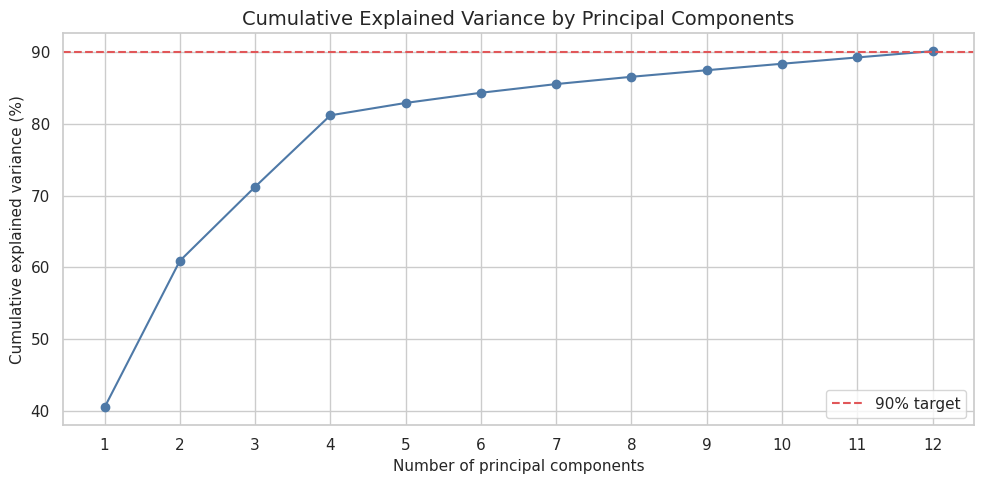

In [38]:
# Explained variance plot
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained) + 1), np.cumsum(explained) * 100, marker="o", color="#4E79A7")
plt.axhline(90, linestyle="--", color="#E15759", label="90% target")
plt.title("Cumulative Explained Variance by Principal Components")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.xticks(range(1, len(explained) + 1))
plt.legend()
plt.tight_layout()
plt.show()

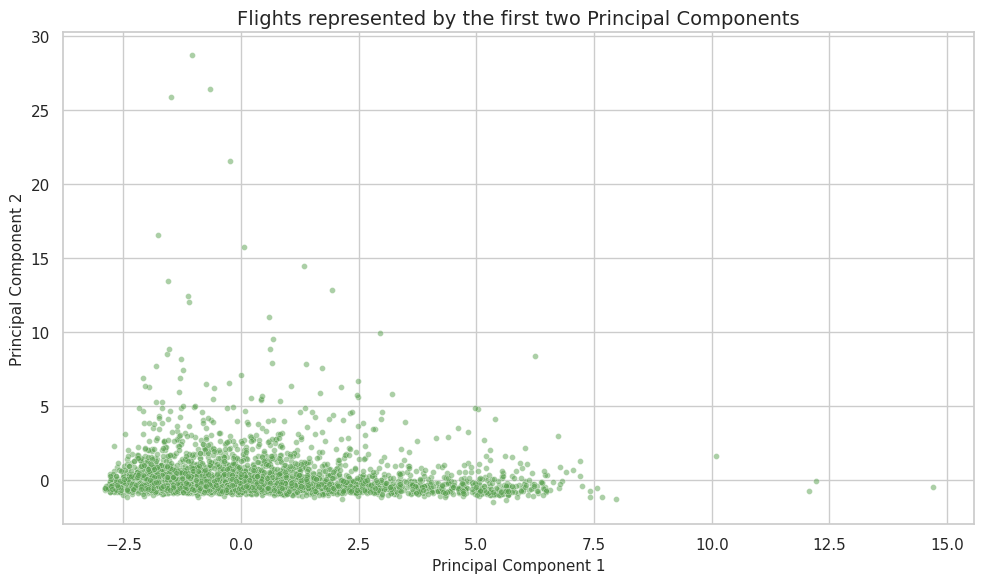

In [39]:
# 2D PCA scatter plot
pca_plot = pd.DataFrame(principal_components[:, :2], columns=["PC1", "PC2"])
plt.figure(figsize=(10, 6))
sns.scatterplot(data=pca_plot.sample(n=min(5000, len(pca_plot)), random_state=42),
                x="PC1", y="PC2", alpha=0.5, s=18, color="#59A14F")
plt.title("Flights represented by the first two Principal Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

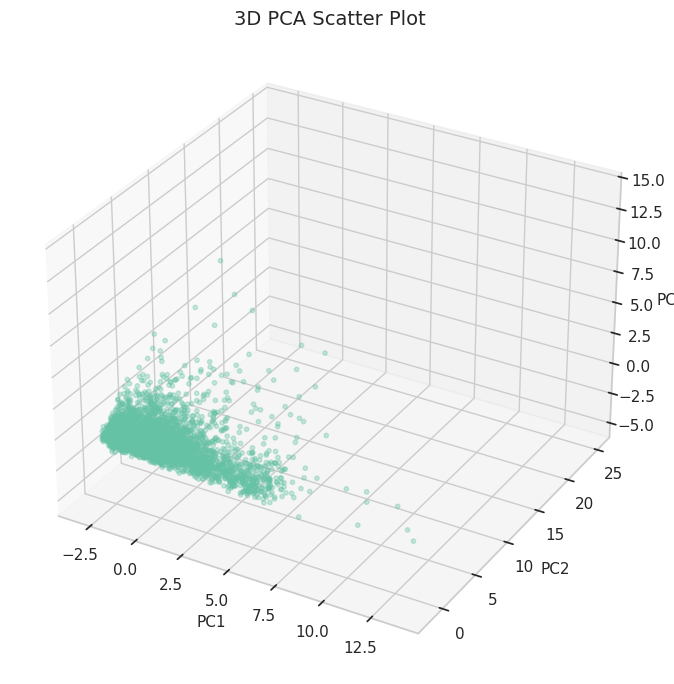

In [40]:
# Optional 3D PCA scatter when at least three components are available
if principal_components.shape[1] >= 3:
    from mpl_toolkits.mplot3d import Axes3D
    plot3d = principal_components[:min(5000, len(principal_components)), :3]
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(plot3d[:, 0], plot3d[:, 1], plot3d[:, 2], alpha=0.35, s=10)
    ax.set_title("3D PCA Scatter Plot")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    plt.tight_layout()
    plt.show()
else:
    print("Three components were not retained at the selected variance threshold; 2D PCA is shown above.")

## 15. Save the cleaned dataset and project outputs
The cleaning rules intentionally retain unusual but potentially genuine flight events. The cleaned CSV may be large and can take time to save.

In [41]:
cleaned_path = "/content/flight_data_2024_cleaned.csv"
df.to_csv(cleaned_path, index=False)
print("Cleaned dataset saved:", cleaned_path)
print("Size (GB):", round(os.path.getsize(cleaned_path) / (1024**3), 2))

Cleaned dataset saved: /content/flight_data_2024_cleaned.csv
Size (GB): 1.46


In [42]:
# Saving supporting analysis tables
missing_report.to_csv("/content/missing_value_report.csv")
iqr_report.to_csv("/content/iqr_outlier_report.csv")
zscore_report.to_csv("/content/zscore_outlier_report.csv")
descriptive_stats.to_csv("/content/descriptive_statistics.csv")
correlation_matrix.to_csv("/content/correlation_matrix.csv")
skew_comparison.to_csv("/content/skewness_before_after.csv")
print("Analysis reports saved in /content/")

Analysis reports saved in /content/


## 16. Final data audit and key findings

In [43]:
print("===== TEAM 10 — FINAL DATA AUDIT =====")
print("Rows:", f"{df.shape[0]:,}")
print("Columns:", df.shape[1])
print("Duplicate rows:", f"{df.duplicated().sum():,}")
print("Missing cells remaining:", f"{df.isna().sum().sum():,}")
if "crs_elapsed_time" in df.columns:
    print("Negative CRS elapsed time:", int((df["crs_elapsed_time"] < 0).sum()))
if "cancelled" in df.columns:
    print("Cancelled flights:", f"{int((df['cancelled'] == 1).sum()):,}")
if "diverted" in df.columns:
    print("Diverted flights:", f"{int((df['diverted'] == 1).sum()):,}")

===== TEAM 10 — FINAL DATA AUDIT =====
Rows: 7,079,081
Columns: 38
Duplicate rows: 0
Missing cells remaining: 1,105,078
Negative CRS elapsed time: 0
Cancelled flights: 96,315
Diverted flights: 17,499
